# Forecasting Daerah Tertinggal by Province

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
import math
from sklearn.linear_model import LinearRegression

In [5]:
df = pd.read_csv('../data/clean_water.csv')

In [6]:
dict_provinsi = {
    'AC': 'Aceh', 'BA': 'Bali', 'BB': 'Kep. Bangka Belitung', 'BE': 'Bengkulu', 
    'BT': 'Banten', 'GO': 'Gorontalo', 'IB': 'Papua Barat', 'JA': 'Jambi',
    'JI': 'Jawa Timur', 'JR': 'Jawa Barat', 'JT': 'Jawa Tengah', 'KB': 'Kalimantan Barat',
    'KI': 'Kalimantan Timur', 'KR': 'Kep. Riau', 'KS': 'Kalimantan Selatan', 
    'KT': 'Kalimantan Tengah', 'KU': 'Kalimantan Utara', 'LA': 'Lampung', 'MA': 'Maluku', 
    'MU': 'Maluku Utara', 'NB': 'Nusa Tenggara Barat', 'NT': 'Nusa Tenggara Timur', 
    'PA': 'Papua', 'RI': 'Riau', 'SB': 'Sumatera Barat', 'SE': 'Sulawesi Selatan', 
    'SG': 'Sulawesi Tenggara', 'SL': 'Sumatera Selatan', 'SR': 'Sulawesi Barat', 
    'ST': 'Sulawesi Tengah', 'SU': 'Sumatera Utara', 'SW': 'Sulawesi Utara', 'YO': 'DI Yogyakarta'
}
df['kode_prov'] = df['id'].astype(str).apply(lambda x: x.split('.')[1] if '.' in x else x)
df['provinsi'] = df['kode_prov'].map(dict_provinsi)

In [ ]:



# Load Hasil Clustering (K-Means) untuk mendapatkan daerah Solid 1 (Cluster 0)
df_cluster = pd.read_csv('Hasil_KMeans_AksesAir.csv')
solid1_daerah = df_cluster[df_cluster['Cluster_KMeans'] == 0]['daerah'].tolist()

print(f"Total Daerah Tertinggal (Solid 1): {len(solid1_daerah)}")

# Load Model XGBoost yang sudah dilatih
with open('Model_AirBersih_.pkl', 'rb') as file:
    model_forecast = pickle.load(file)
    
# FIX: OneHotEncoder drop='first' on 'year' causes error for future years.
# We will temporarily change handle_unknown to 'ignore' to prevent error on unknown years like 2025
model_forecast.named_steps['preprocessing'].transformers_[0][1].handle_unknown = 'ignore'


Total Daerah Tertinggal (Solid 1): 33


In [2]:
def project_feature(df_daerah, feature, years_future):
    X = df_daerah['year'].values.reshape(-1, 1)
    y = df_daerah[feature].values
    reg = LinearRegression().fit(X, y)
    return reg.predict(np.array(years_future).reshape(-1, 1))

forecast_years = [2025, 2030, 2040, 2045]
all_forecasts = []

for daerah in solid1_daerah:
    df_d = df[df['daerah'] == daerah].sort_values('year')
    if df_d.empty: continue
    
    # Ambil data tahun 2020 sebagai base
    df_2020_rows = df_d[df_d['year'] == 2020]
    if df_2020_rows.empty:
        last_row = df_d.iloc[-1]
    else:
        last_row = df_2020_rows.iloc[0]

    for yr in forecast_years:
        row = {
            'year': yr,
            'daerah': daerah,
            'tingkat': last_row['tingkat'],
            'status': last_row['status'],
            'logpop': project_feature(df_d, 'logpop', [yr])[0],
            'logarea': float(last_row['logarea']),
            'logpad': project_feature(df_d, 'logpad', [yr])[0],
            'morbid': project_feature(df_d, 'morbid', [yr])[0],
        }
        all_forecasts.append(row)

df_forecast = pd.DataFrame(all_forecasts)

# Lakukan prediksi menggunakan model .pkl
features_order = ['logpop', 'logarea', 'logpad', 'year', 'morbid', 'daerah', 'tingkat', 'status']
df_forecast['water'] = model_forecast.predict(df_forecast[features_order])
# Batasi nilai persentase di rentang [0, 100]
df_forecast['water'] = df_forecast['water'].clip(0, 100)


/Users/yudhapratama/Documents/Science/Publikasi/clean-water-access/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


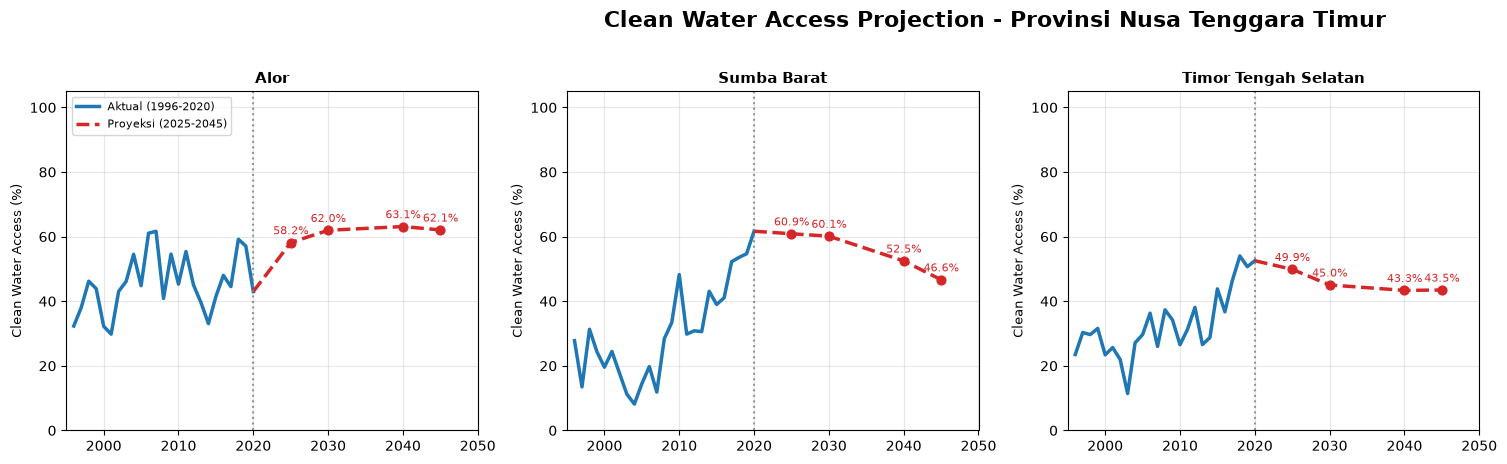

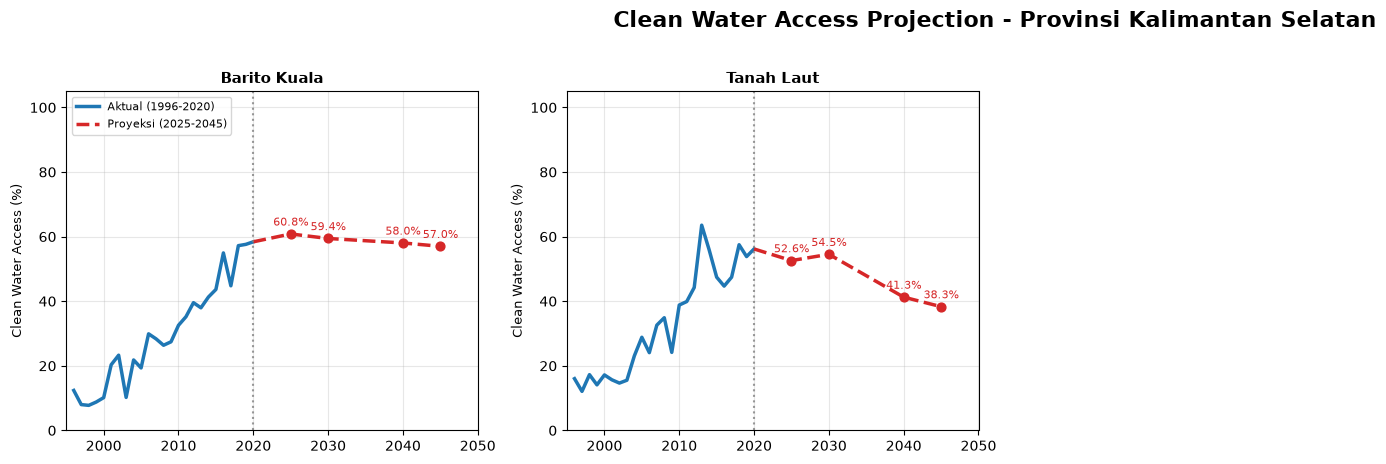

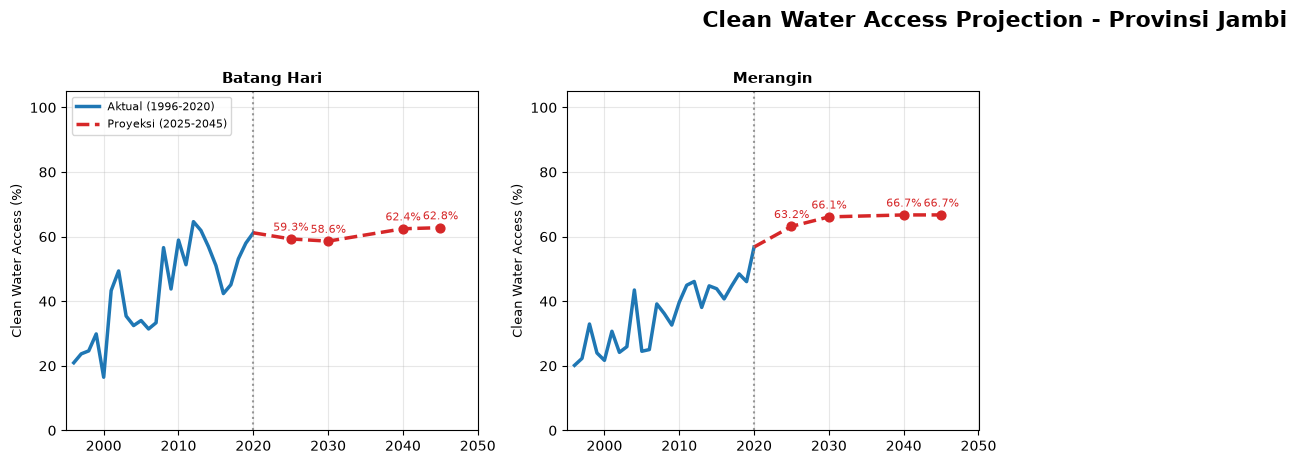

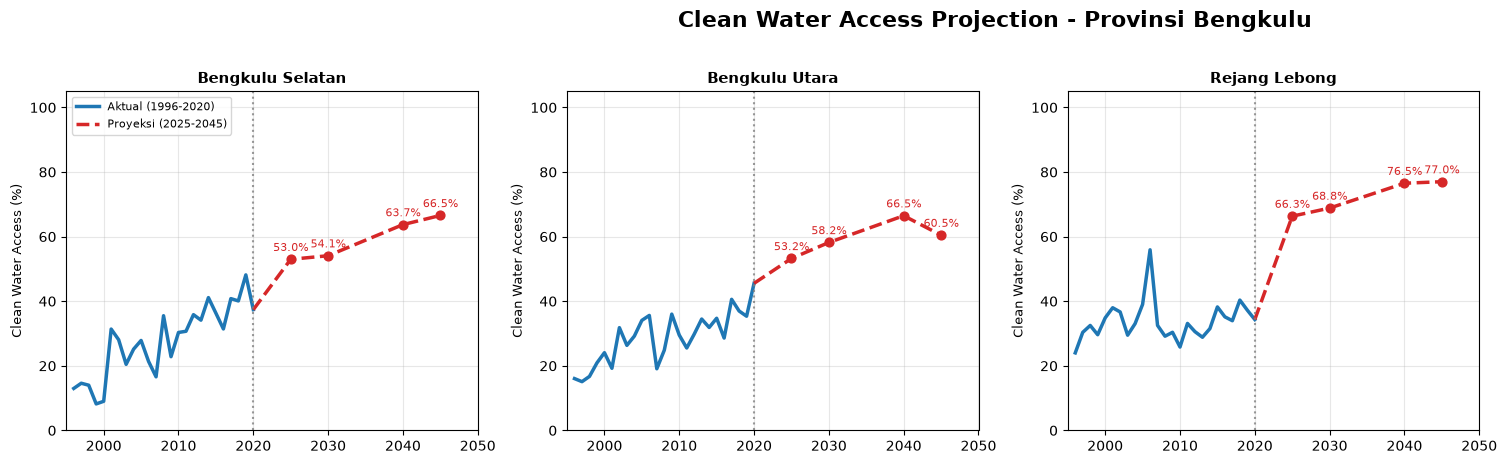

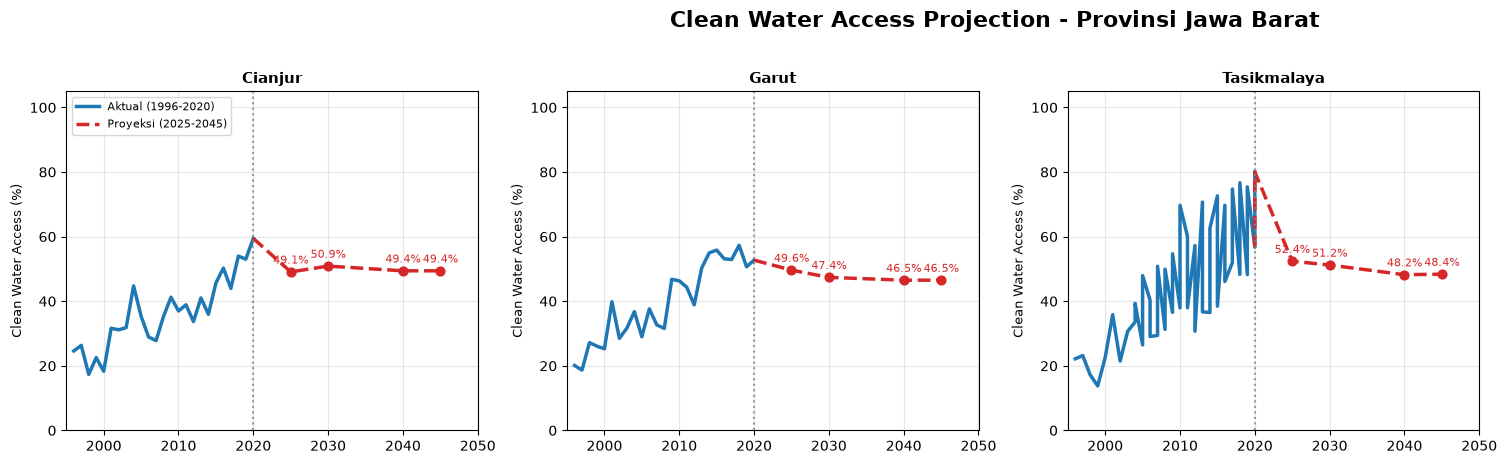

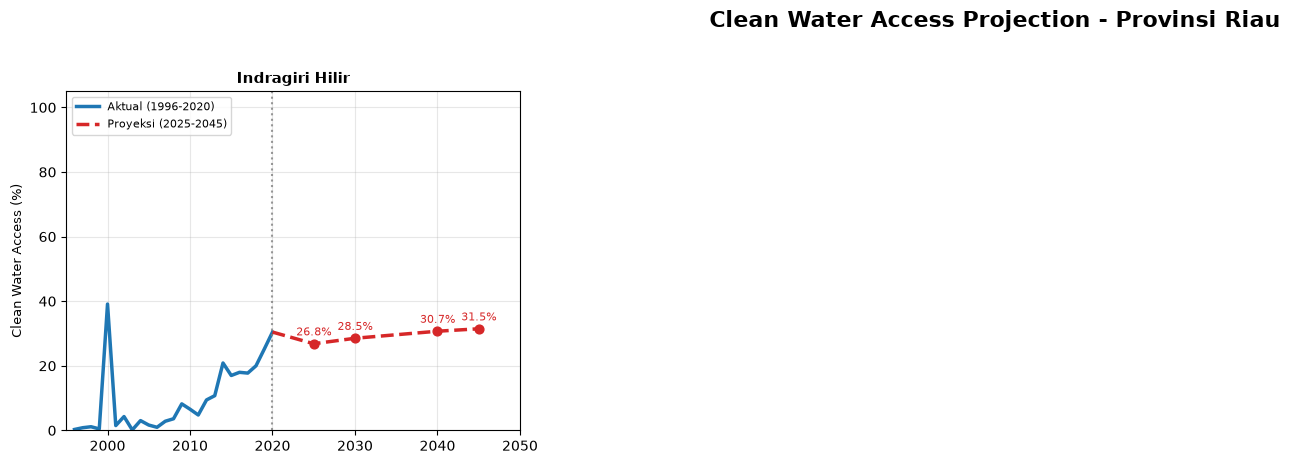

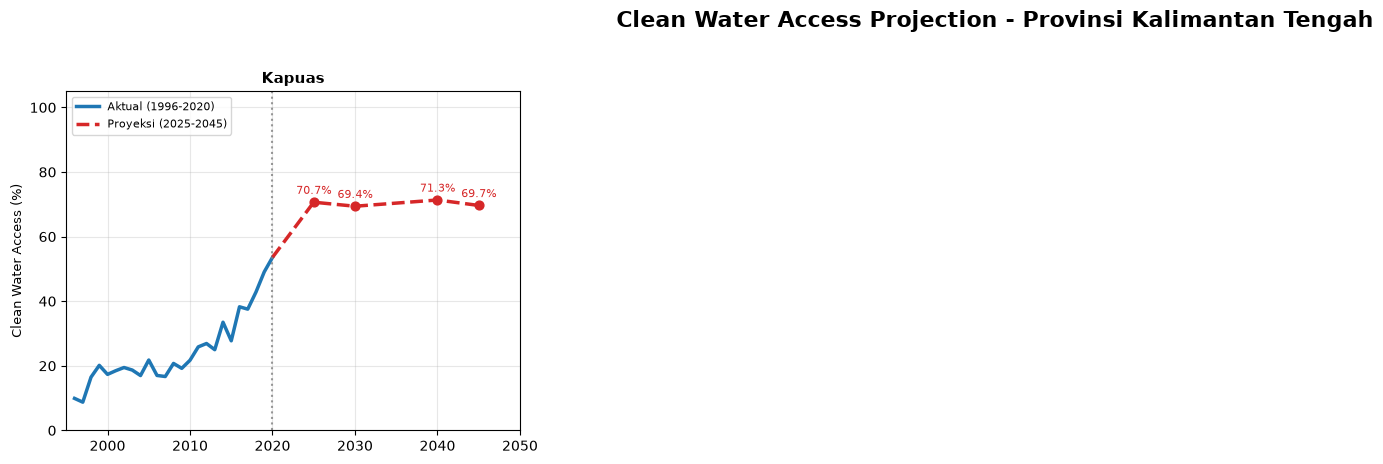

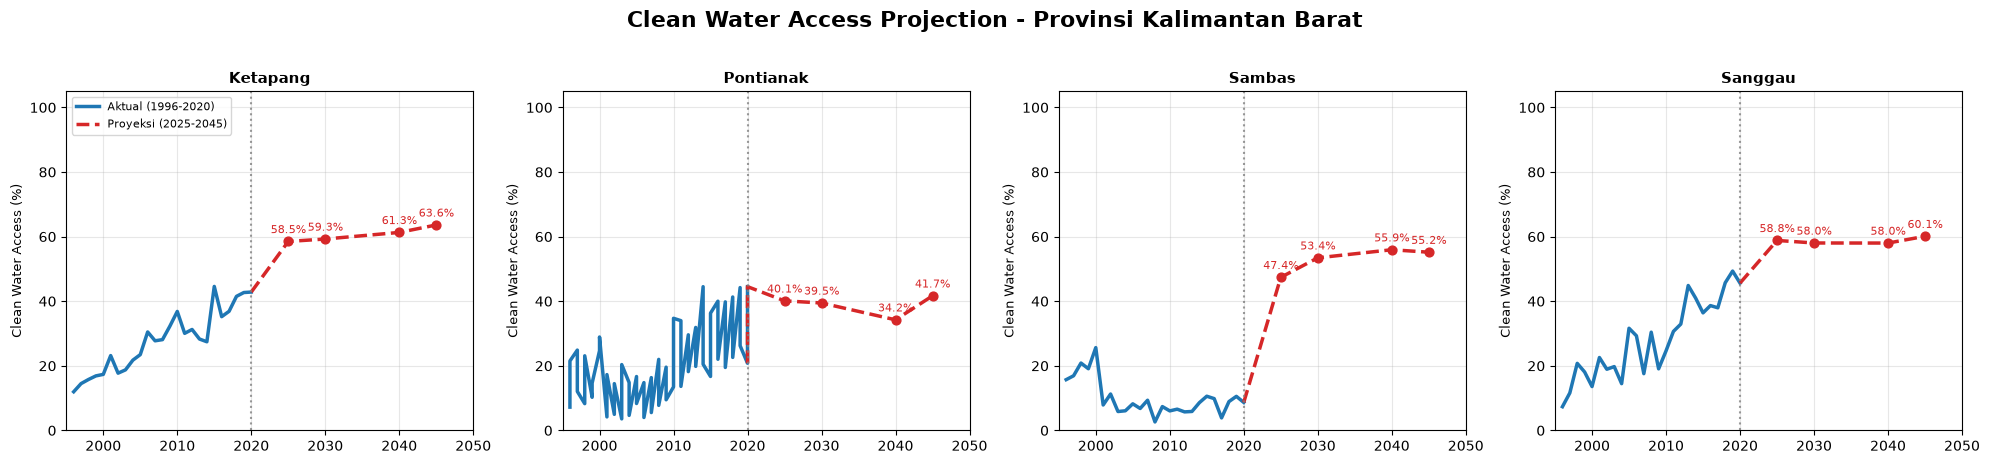

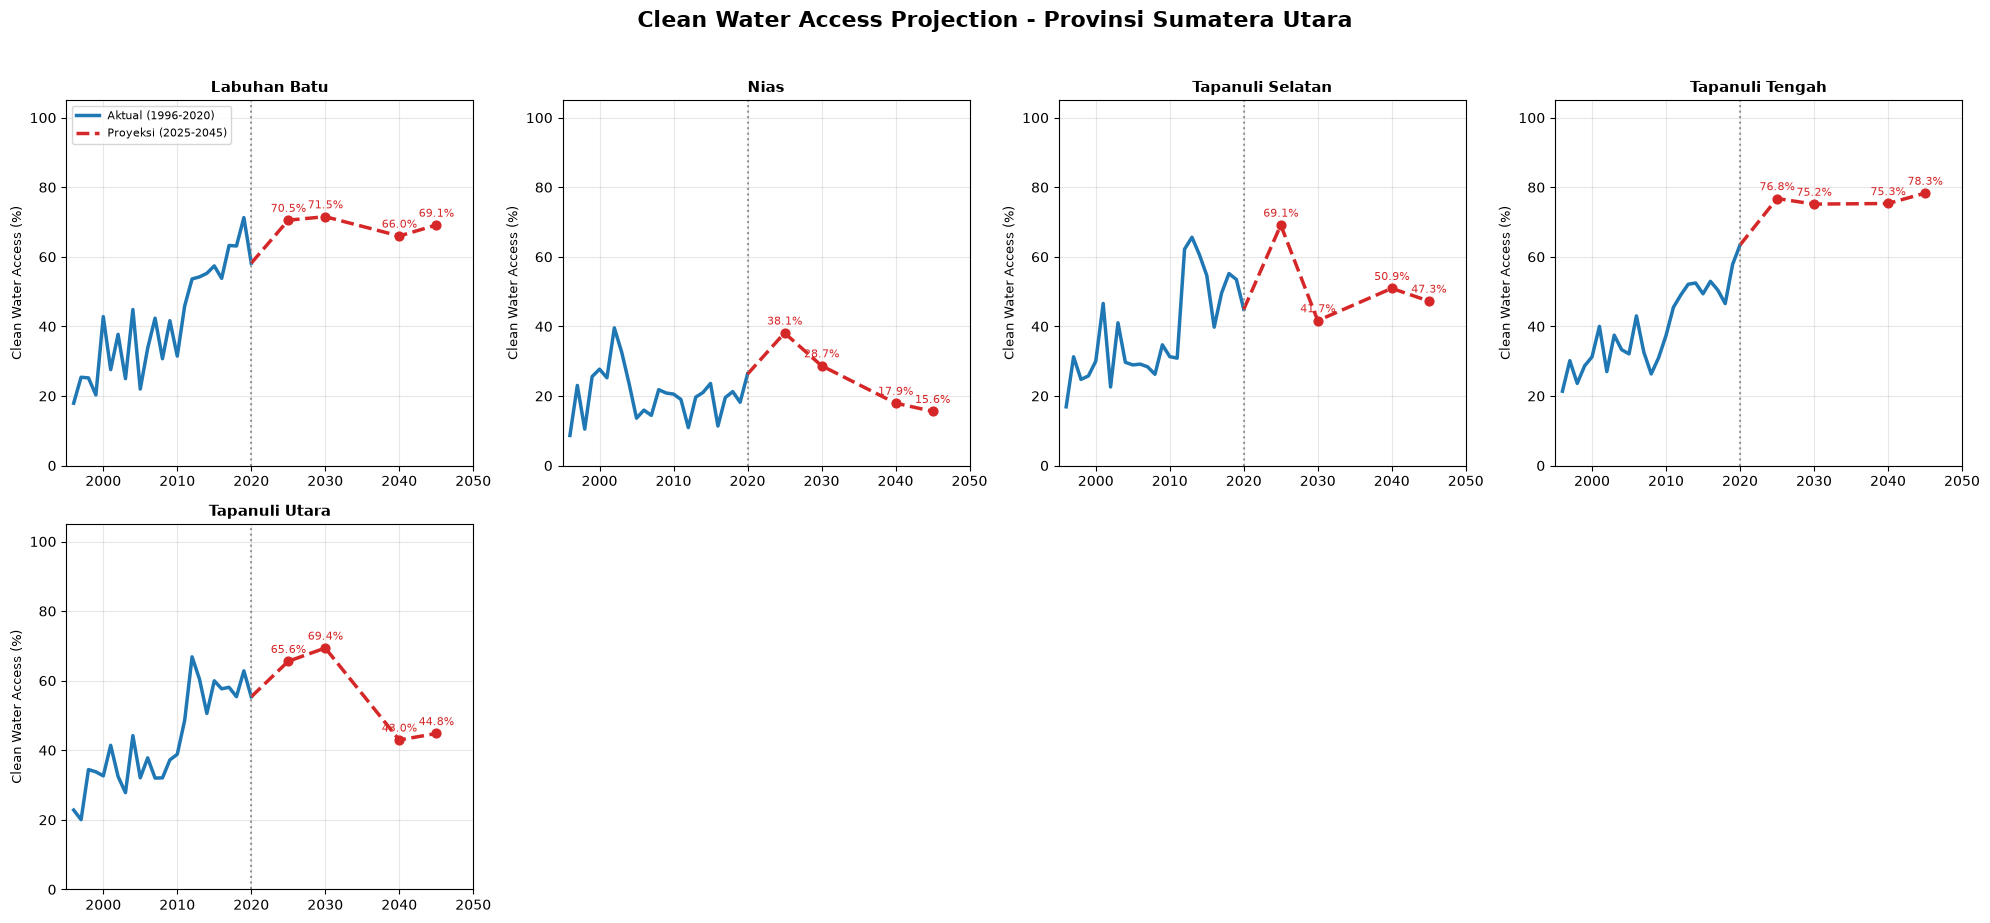

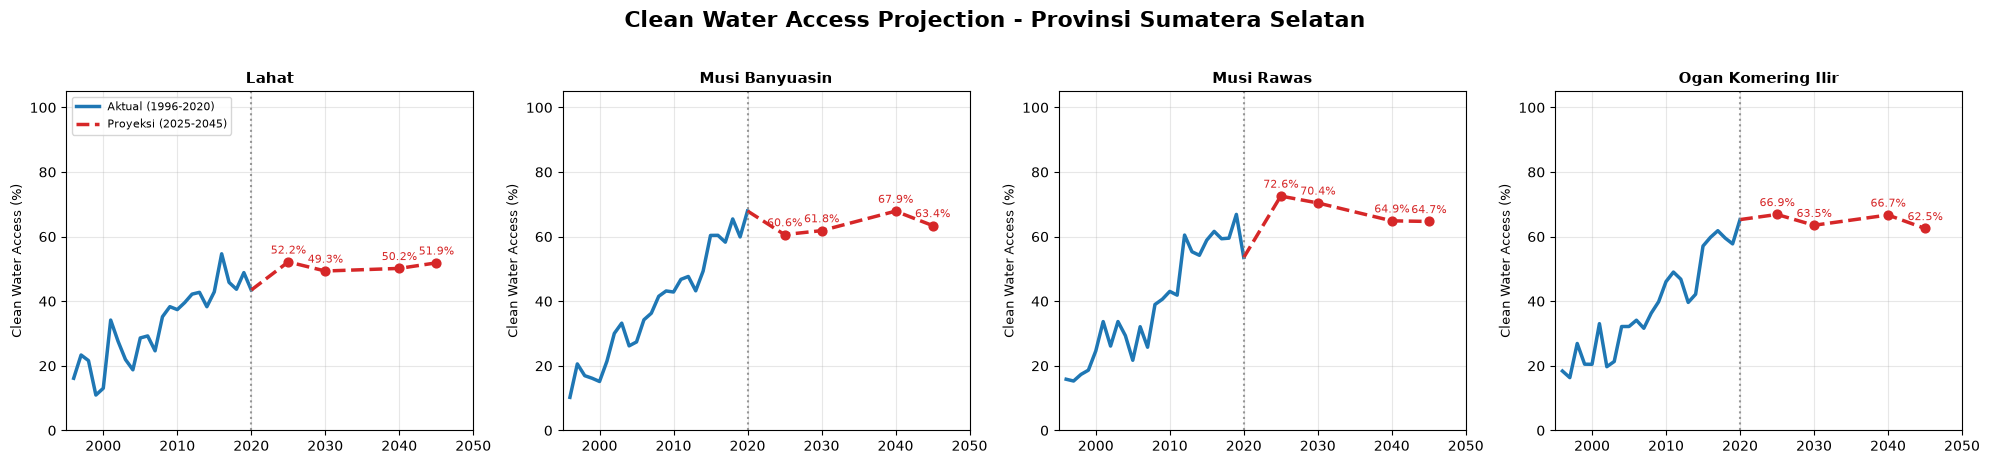

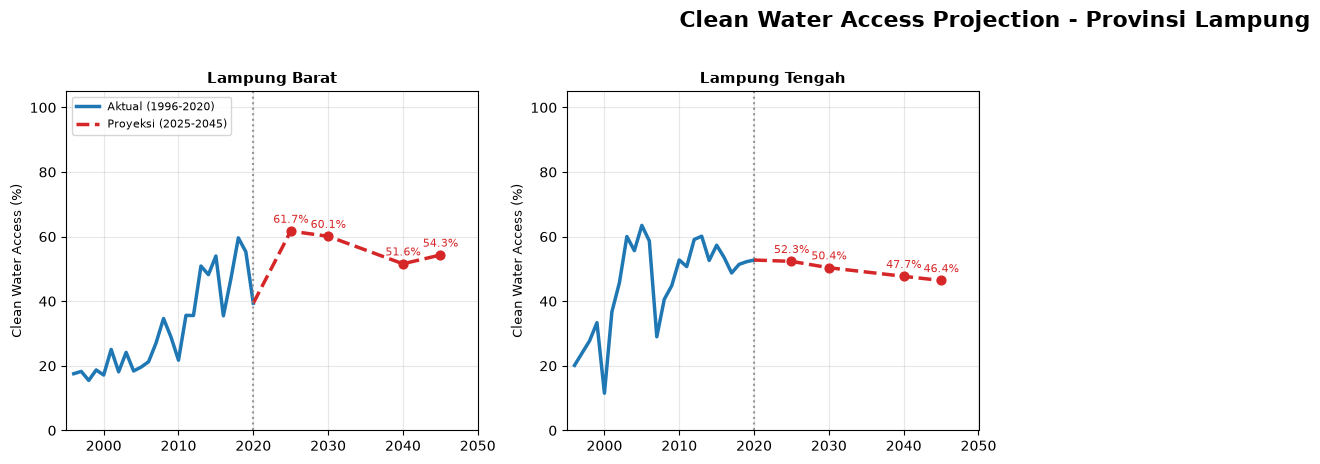

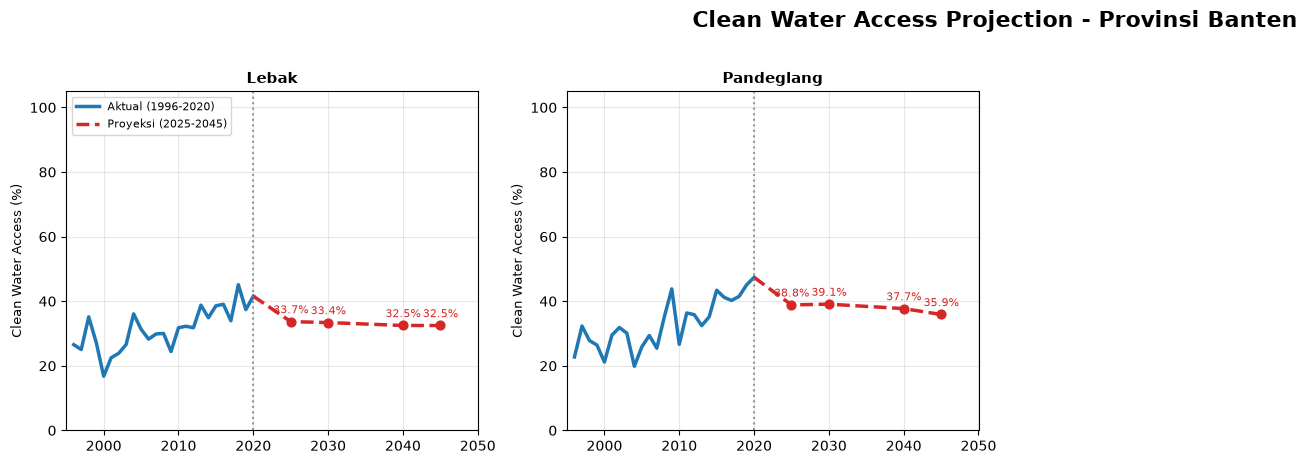

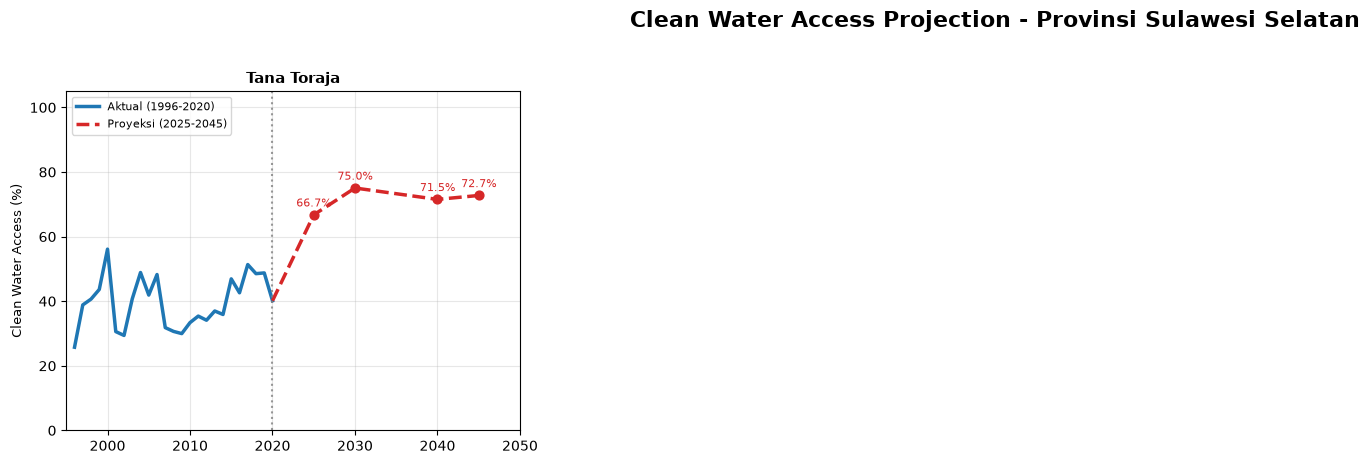

In [3]:

# Kelompokkan daerah berdasarkan provinsi
provinsi_daerah = {}
for daerah in solid1_daerah:
    provs = df[df['daerah'] == daerah]['provinsi'].dropna().unique()
    prov = provs[0] if len(provs) > 0 else 'Unknown'
    if prov not in provinsi_daerah:
        provinsi_daerah[prov] = []
    provinsi_daerah[prov].append(daerah)

# Visualisasi per provinsi
for prov, daerah_list in provinsi_daerah.items():
    ncols = 4
    nrows = math.ceil(len(daerah_list) / ncols)
    
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(20, nrows * 4.5))
    axes = np.atleast_1d(axes).flatten()

    for i, daerah in enumerate(daerah_list):
        ax = axes[i]
        
        # Ambil data aktual (1996 - 2020)
        actual_data = df[df['daerah'] == daerah].sort_values('year')[['year', 'water']]
        
        # Ambil data forecast (2025, 2030, 2040, 2045)
        forecast_data = df_forecast[df_forecast['daerah'] == daerah].sort_values('year')[['year', 'water']]
        
        if forecast_data.empty or actual_data.empty:
            continue
            
        # Ambil titik terakhir dari aktual sebagai penyambung garis
        last_actual = actual_data[actual_data['year'] == actual_data['year'].max()]
        
        # Gabungkan titik aktual terakhir dengan data forecast agar garis bersambung
        connected_forecast = pd.concat([last_actual, forecast_data]).reset_index(drop=True)
        
        # Plot Actual (Solid Line)
        ax.plot(actual_data['year'], actual_data['water'], color='#1f77b4', lw=2.5, label='Aktual (1996-2020)')
        
        # Plot Forecast (Dashed Line)
        ax.plot(connected_forecast['year'], connected_forecast['water'], color='#d62728', lw=2.5, ls='--', label='Proyeksi (2025-2045)')
        
        # Tambahkan marker bulat di titik-titik forecast
        ax.scatter(forecast_data['year'], forecast_data['water'], color='#d62728', s=40, zorder=5)
        
        # Beri label persentase pada titik forecast
        for _, row in forecast_data.iterrows():
            ax.annotate(f"{row['water']:.1f}%",
                        xy=(row['year'], row['water']),
                        xytext=(0, 6), textcoords='offset points',
                        ha='center', fontsize=8, color='#d62728')
        
        # Garis pembatas tahun 2020
        ax.axvline(2020, color='gray', ls=':', alpha=0.8)
        
        ax.set_title(daerah, fontsize=11, fontweight='bold')
        ax.set_ylim(0, 105)
        ax.set_xlim(1995, 2050)
        ax.set_ylabel('Clean Water Access (%)', fontsize=9)
        ax.grid(True, alpha=0.3)
        
        if i == 0:
            ax.legend(fontsize=8, loc='upper left')

    # Sembunyikan axes yang tidak terpakai
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)

    plt.suptitle(f'Clean Water Access Projection - Provinsi {prov}', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()